## Problem statement 


#### How far could ensemble learning methods (Random Forest Regressor and XG Boost Regressor), predict state level prevalence rates of obesity related health indicators.
#### what happens as they are trained on a multi-dimensional feature set including temporal, demographic, geographic, and survey specific Question ID. how do the results of relative feature importance analyses of two models drawn from the resulting results point to the most predictive factors for model performance as measured by RMSE, MAE, and R² scores?



## 1.Introduction and Dataset Overview



#### Dataset Name:Nutrition, Physical Activity, and Obesity - Behavioral Risk Factor Surveillance System
#### Source: https://catalog.data.gov/dataset/nutrition-physical-activity-and-obesity-behavioral-risk-factor-surveillance-system
#### Purpose: Predict prevalence rates of health metrics (e.g., obesity, physical activity) across US states.
#### Problem Type: Regression
#### Target Variable: PrevalenceRate (percentage, continuous, 0–100)
#### Key Features:
##### *YearStart: Year of data collection.
##### *Sample_Size: Number of respondents.
##### *Class: Health behavior category (e.g., Obesity, Physical Activity).
##### *Location state based
##### *Stratification1: Demographic group
##### *QuestionID, Question: Health question identifier and text.
##### *GeoLocation: Geographic coordinates (parsed into Latitude, Longitude).

## Import necessary libraries 


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBRegressor
import statsmodels.nonparametric.smoothers_lowess as lowess
sns.set_theme()

##  2. Data Preprocessing and Cleaning

### 2.1 Initial Data Exploration

In [8]:
# Loading the dataset 
df = pd.read_csv('Obesity_adult.csv')

In [9]:
# Displaying the  basic information from the dataset
print("Dataset Info: ")
print(df.info())

Dataset Info: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104272 entries, 0 to 104271
Data columns (total 33 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   YearStart                   104272 non-null  int64  
 1   YearEnd                     104272 non-null  int64  
 2   LocationAbbr                104272 non-null  object 
 3   LocationDesc                104272 non-null  object 
 4   Datasource                  104272 non-null  object 
 5   Class                       104272 non-null  object 
 6   Topic                       104272 non-null  object 
 7   Question                    104272 non-null  object 
 8   Data_Value_Unit             88872 non-null   float64
 9   Data_Value_Type             104272 non-null  object 
 10  Data_Value                  93505 non-null   float64
 11  Data_Value_Alt              93505 non-null   float64
 12  Data_Value_Footnote_Symbol  10767 non-null   object 
 13 

In [10]:
# Displaying first few rows the initial checks 
print("First 5 Rows :")
df.head()

First 5 Rows :


,YearStart,YearEnd,LocationAbbr,LocationDesc,Datasource,Class,Topic,Question,Data_Value_Unit,Data_Value_Type,...,GeoLocation,ClassID,TopicID,QuestionID,DataValueTypeID,LocationID,StratificationCategory1,Stratification1,StratificationCategoryId1,StratificationID1
0,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Race/Ethnicity,2 or more races,RACE,RACE2PLUS
1,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Race/Ethnicity,Other,RACE,RACEOTH
2,2011,2011,AK,Alaska,BRFSS,Physical Activity,Physical Activity - Behavior,Percent of adults who achieve at least 150 min...,2011.0,Value,...,"(64.845079957001, -147.722059036)",PA,PA1,Q044,VALUE,2,Sex,Female,SEX,FEMALE
3,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Age (years),35 - 44,AGEYR,AGEYR3544
4,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q037,VALUE,2,Income,"$15,000 - $24,999",INC,INC1525


In [11]:
# Check missing values
print("\nMissing Values (%):")
print((df.isnull().mean() * 100).round(2))



Missing Values (%):
YearStart                      0.00
YearEnd                        0.00
LocationAbbr                   0.00
LocationDesc                   0.00
Datasource                     0.00
Class                          0.00
Topic                          0.00
Question                       0.00
Data_Value_Unit               14.77
Data_Value_Type                0.00
Data_Value                    10.33
Data_Value_Alt                10.33
Data_Value_Footnote_Symbol    89.67
Data_Value_Footnote           89.67
Low_Confidence_Limit          10.33
High_Confidence_Limit         10.33
Sample_Size                   10.33
Total                         96.43
Age(years)                    78.57
Education                     85.71
Sex                           92.86
Income                        75.00
Race/Ethnicity                71.43
GeoLocation                    1.85
ClassID                        0.00
TopicID                        0.00
QuestionID                     0.00
DataVal

In [12]:
# Rename the Target varible (Data_Value) to PrevalenceRate  for convinience 

df = df.rename(columns={'Data_Value': 'PrevalenceRate'})


In [13]:
# Display the first 5 rows of the DataFrame
df.head()

,YearStart,YearEnd,LocationAbbr,LocationDesc,Datasource,Class,Topic,Question,Data_Value_Unit,Data_Value_Type,...,GeoLocation,ClassID,TopicID,QuestionID,DataValueTypeID,LocationID,StratificationCategory1,Stratification1,StratificationCategoryId1,StratificationID1
0,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Race/Ethnicity,2 or more races,RACE,RACE2PLUS
1,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Race/Ethnicity,Other,RACE,RACEOTH
2,2011,2011,AK,Alaska,BRFSS,Physical Activity,Physical Activity - Behavior,Percent of adults who achieve at least 150 min...,2011.0,Value,...,"(64.845079957001, -147.722059036)",PA,PA1,Q044,VALUE,2,Sex,Female,SEX,FEMALE
3,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Age (years),35 - 44,AGEYR,AGEYR3544
4,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,2011.0,Value,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q037,VALUE,2,Income,"$15,000 - $24,999",INC,INC1525


### 2.2 Handling Missing Data

1.Dropping the  columns with high missing values  (Total, Age(years), Education, Data_Value_Unit)

2.Fill PrevalenceRate using median grouped by class to get more data

3.Replace missing numerical columns (Sample_Size) with median

4.Substitute missing categorical columns (Class,LocationAbbr,stratification1,QuestionID) with mode

In [16]:
# 1.Dropping the  columns with high missing values  (Total, Age(years), Education, Data_Value_Unit)
high_missing_col =["Total","Age(years)","Education","Sex","Data_Value_Unit"]
df= df.drop(columns=[col for col in high_missing_col if col in df.columns] )

In [17]:
# 2.Fill PrevalenceRate using median grouped by class to get more data.
if df["PrevalenceRate"].isnull().any() and "Class" in df.columns:
    df["PrevalenceRate"]= df.groupby('Class')['PrevalenceRate'].transform(lambda x:x.fillna(x.median()))
    df["PrevalenceRate"]=df['PrevalenceRate'].fillna(df["PrevalenceRate"].median())


In [18]:
# 3.Replace missing numerical columns (Sample_Size) with median

numerical_cols=["Sample_Size"]
available_numerical_cols=[col for col in numerical_cols if col in df.columns]
if not available_numerical_cols:
    print("The specified numerical columns has not found. Available columns are: ",df.columns.tolist())
else:
    for col in available_numerical_cols:
        df[col]= df[col].fillna(df[col].median())


In [19]:
# 4.Substitute missing categorical columns (Class,LocationAbbr,Stratification1,QuestionID) with mode

categorical_col=["Class", "LocationAbbr", "Stratification1", "QuestionID"]
for col in categorical_col:
    if col in df.columns:
        df[col]=df[col].fillna(df[col].mode()[0])


In [20]:
df.head()

,YearStart,YearEnd,LocationAbbr,LocationDesc,Datasource,Class,Topic,Question,Data_Value_Type,PrevalenceRate,...,GeoLocation,ClassID,TopicID,QuestionID,DataValueTypeID,LocationID,StratificationCategory1,Stratification1,StratificationCategoryId1,StratificationID1
0,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,23.3,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Race/Ethnicity,2 or more races,RACE,RACE2PLUS
1,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,35.5,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Race/Ethnicity,Other,RACE,RACEOTH
2,2011,2011,AK,Alaska,BRFSS,Physical Activity,Physical Activity - Behavior,Percent of adults who achieve at least 150 min...,Value,21.7,...,"(64.845079957001, -147.722059036)",PA,PA1,Q044,VALUE,2,Sex,Female,SEX,FEMALE
3,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,29.5,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q036,VALUE,2,Age (years),35 - 44,AGEYR,AGEYR3544
4,2011,2011,AK,Alaska,BRFSS,Obesity / Weight Status,Obesity / Weight Status,Percent of adults aged 18 years and older who ...,Value,33.5,...,"(64.845079957001, -147.722059036)",OWS,OWS1,Q037,VALUE,2,Income,"$15,000 - $24,999",INC,INC1525



### 2.3 Handling Outliers

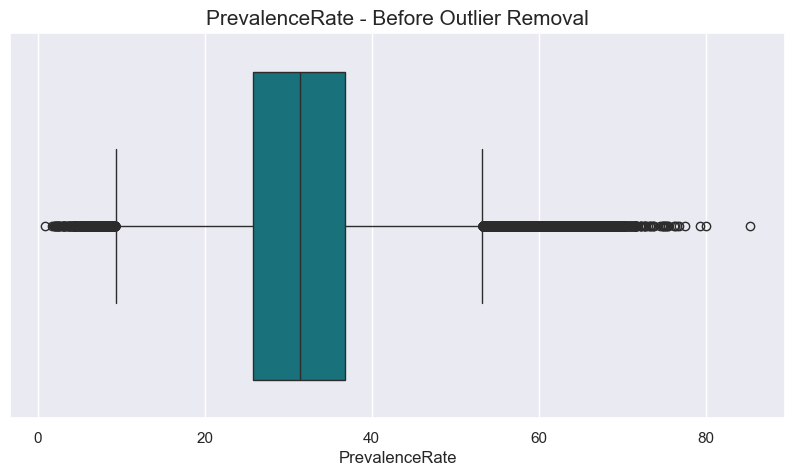

In [22]:
# Plot Prevalence Rate before outlier removal
plt.figure(figsize=(10,5))
sns.boxplot(x=df['PrevalenceRate'],color="#087E8B")
plt.title("PrevalenceRate - Before Outlier Removal",size=15)
plt.xlabel("PrevalenceRate")
plt.show()

In [23]:
# Handling Outliers (IQR Filtering) on PrevalenceRate

print("Handling Outliers (IQR Filtering) on PrevalenceRate")
def remove_outliers_iqr(data,column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound =Q1 - 1.5 * IQR
    upper_bound =Q3 + 1.5 * IQR
    return data[(data[column] >=lower_bound) & (data[column] <= upper_bound)]

before_shape =df.shape
df =remove_outliers_iqr(df,"PrevalenceRate")
after_shape=df.shape

print(f"Data shape before outlier removal: {before_shape}")
print(f"Data shape after IQR based outlier removal: {after_shape}")


Handling Outliers (IQR Filtering) on PrevalenceRate
Data shape before outlier removal: (104272, 28)
Data shape after IQR based outlier removal: (100230, 28)


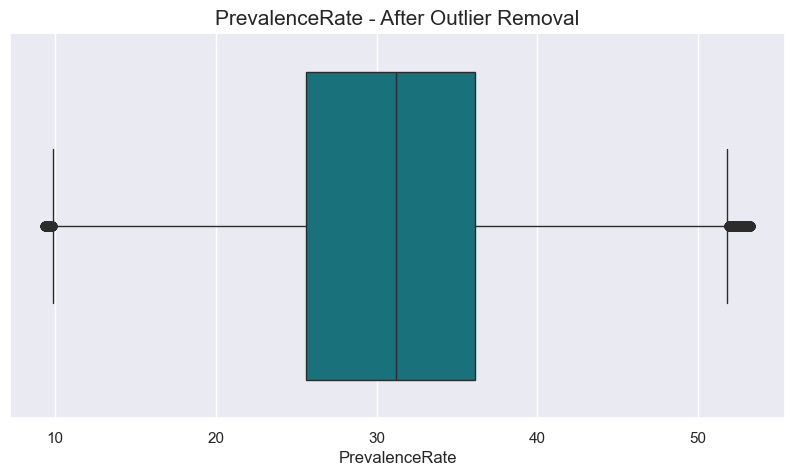

In [24]:
# Plot PrevalenceRate after outlier removal
plt.figure(figsize=(10,5))
sns.boxplot(x=df['PrevalenceRate'],color="#087E8B")
plt.title("PrevalenceRate - After Outlier Removal",size=15)
plt.xlabel("PrevalenceRate")
plt.show()


### 2.4 Feature Engineering & Transformation

In [26]:
# Encoding the categorical variables 
le =LabelEncoder()
for col in ["Class","LocationAbbr","Stratification1","QuestionID"]:
    if col in df.columns:
        df[col + "_encoded"] = le.fit_transform(df[col])
    else:
        print(f" Column {col} not found for encoding")

In [27]:
# Parse GeoLocation into Latitude and Longitude for numerical modeling
if "GeoLocation"in df.columns:
    def parse_geolocation(geo):
        try:
            lat,lon =geo.strip("()").split(",")
            return float(lat), float(lon)
        except:
            return np.nan,np.nan
    df["Latitude"], df["Longitude"] =zip(*df["GeoLocation"].apply(parse_geolocation))
    df["Latitude"]=df["Latitude"].fillna(df["Latitude"].median())
    df["Longitude"]=df["Longitude"].fillna(df["Longitude"].median())
else:
    print("GeoLocation column not found")

In [28]:
# Feature selection

features=['YearStart','Sample_Size','Class_encoded','LocationID','LocationAbbr_encoded','Stratification1_encoded','QuestionID_encoded','Latitude','Longitude']
target ='PrevalenceRate'

In [29]:
# checking all features are exist or not 
features =[f for f in features if f in df.columns or (f.endswith('_encoded') and f.replace('_encoded', '') in df.columns)]

In [30]:

# Apply log transformation to Sample_Size to handle skewness

if 'Sample_Size' in df.columns:
    df['Sample_Size'] =np.log1p(df['Sample_Size']) 

In [31]:
# Create feature matrix X and target vector y
X =df[features]
y =df[target]

# Display feature matrix
print("\nFeature Matrix Shape:", X.shape)
print("\nFeature Matrix Head:")
X.head()



Feature Matrix Shape: (100230, 9)

Feature Matrix Head:


,YearStart,Sample_Size,Class_encoded,LocationID,LocationAbbr_encoded,Stratification1_encoded,QuestionID_encoded,Latitude,Longitude
0,2011,4.859812,1,2,0,6,2,64.84508,-147.722059
1,2011,4.158883,1,2,0,25,2,64.84508,-147.722059
2,2011,7.440147,2,2,0,16,5,64.84508,-147.722059
3,2011,6.333280,1,2,0,8,2,64.84508,-147.722059
4,2011,5.934894,1,2,0,0,3,64.84508,-147.722059


In [32]:
# Updating the matrix after transformation
X = df[features]
y = df[target]

# Verifing the data after transformation
print("\nData Description After Transformation:")
print(df[features + [target]].describe())



Data Description After Transformation:
           YearStart    Sample_Size  Class_encoded     LocationID  \
count  100230.000000  100230.000000  100230.000000  100230.000000   
mean     2016.988576       6.974035       1.428794      31.035079   
std         3.710471       1.252282       0.652303      17.537584   
min      2011.000000       3.931826       0.000000       1.000000   
25%      2014.000000       6.324359       1.000000      17.000000   
50%      2017.000000       6.990257       2.000000      30.000000   
75%      2020.000000       7.667158       2.000000      45.000000   
max      2023.000000      13.075014       2.000000      78.000000   

       LocationAbbr_encoded  Stratification1_encoded  QuestionID_encoded  \
count         100230.000000            100230.000000       100230.000000   
mean              26.785014                13.532366            4.410945   
std               15.765498                 8.089230            2.507638   
min                0.000000       

### 3. Exploratory Data Analysis (EDA)


Insight:Prevalence Rate distribution shows the range of obesity/physical activity percentages with the potential skewness


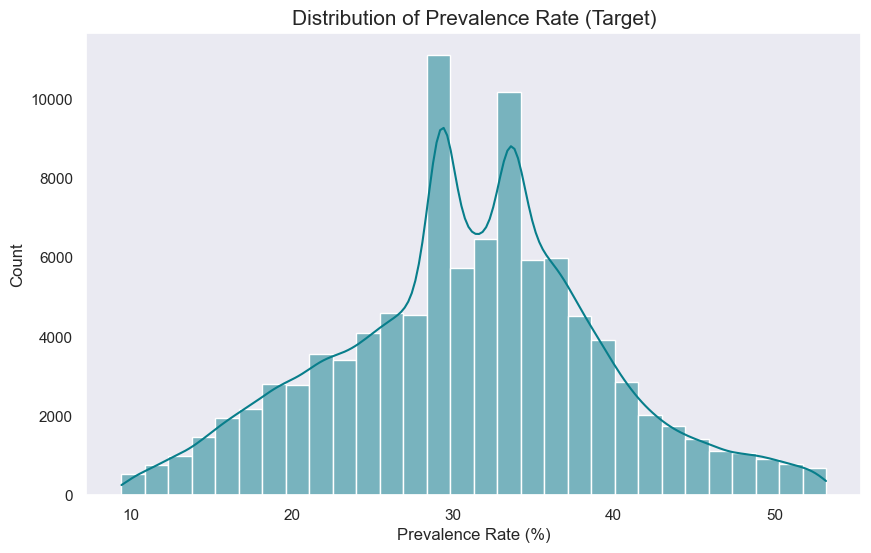

In [34]:
# 3.1 Distribution of Target Variable

plt.figure(figsize=(10, 6))
sns.histplot(df['PrevalenceRate'], bins=30, kde=True, color='#087E8B')
plt.title('Distribution of Prevalence Rate (Target)', size=15)
plt.xlabel('Prevalence Rate (%)')
plt.ylabel('Count')
plt.grid(False) 
print("\nInsight:Prevalence Rate distribution shows the range of obesity/physical activity percentages with the potential skewness")
plt.show()
plt.close()



Insight:Correlation matrix


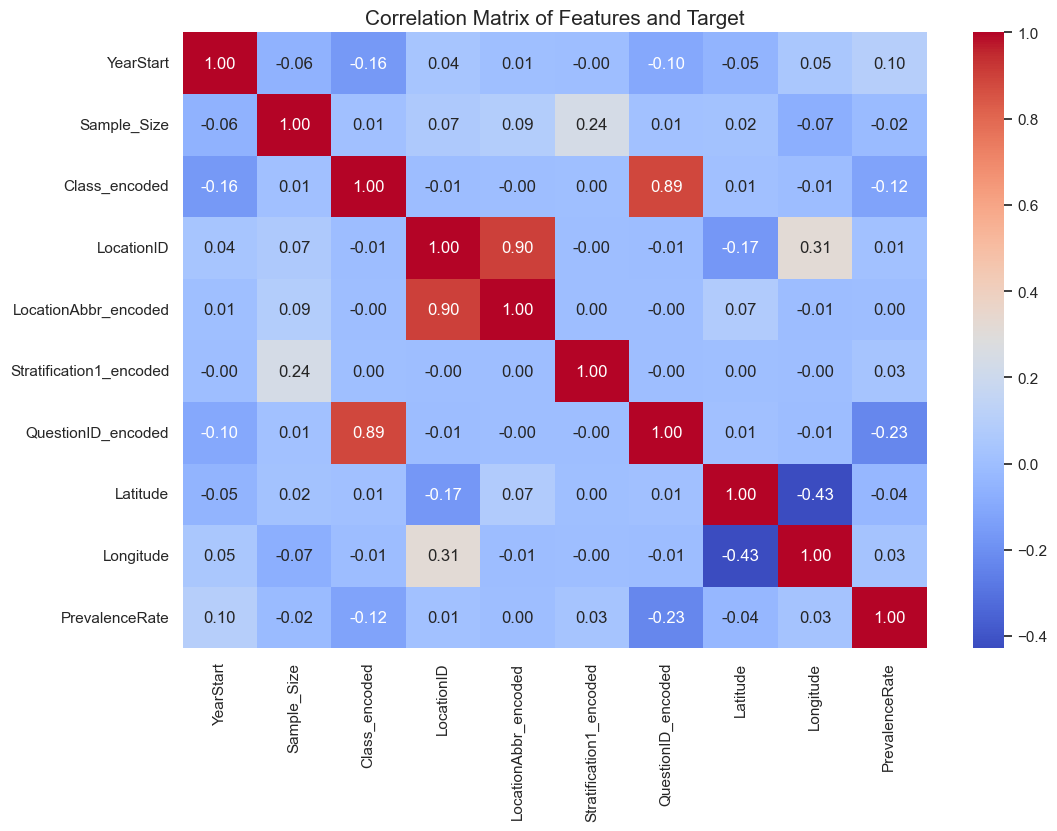

In [35]:

# 3.2 Correlation Analysis
corr_matrix = df[features + [target]].corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',fmt='.2f')
plt.title("Correlation Matrix of Features and Target",size=15)
print("\nInsight:Correlation matrix")
plt.show()
plt.close()



Insight:Average Prevalence Rate Over Time by Class


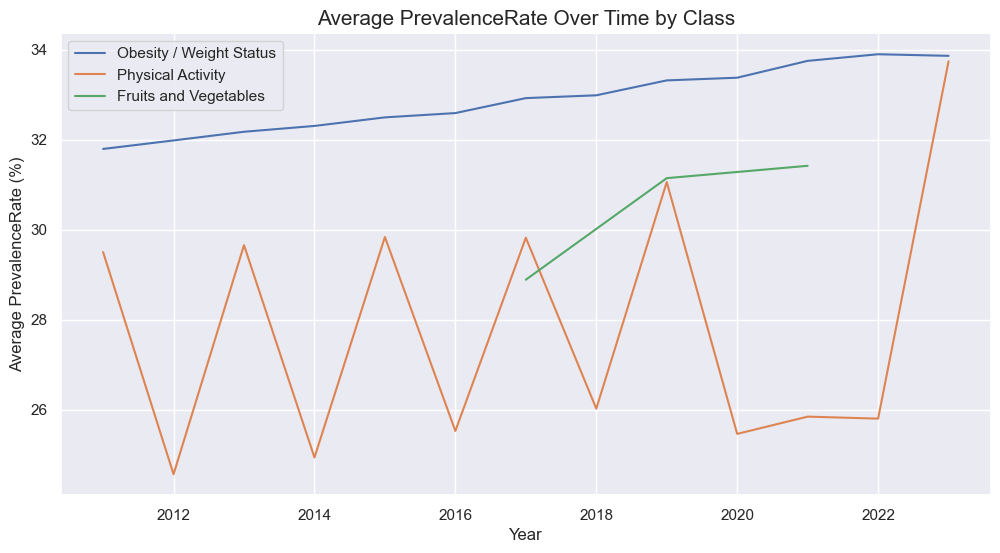

In [36]:
# 3.3 Average Prevalence Rate Over Time by Class
plt.figure(figsize=(12, 6))
for class_name in df['Class'].unique():
    class_data = df[df['Class'] == class_name].groupby('YearStart')['PrevalenceRate'].mean()
    plt.plot(class_data.index, class_data.values, label=class_name)
plt.title('Average PrevalenceRate Over Time by Class', size=15)
plt.xlabel('Year')
plt.ylabel('Average PrevalenceRate (%)')
plt.legend()
print("\nInsight:Average Prevalence Rate Over Time by Class")
plt.show()
plt.close()


Insight: Bar graph shows states with highest and lowest obesity rates, highlighting regional health disparities



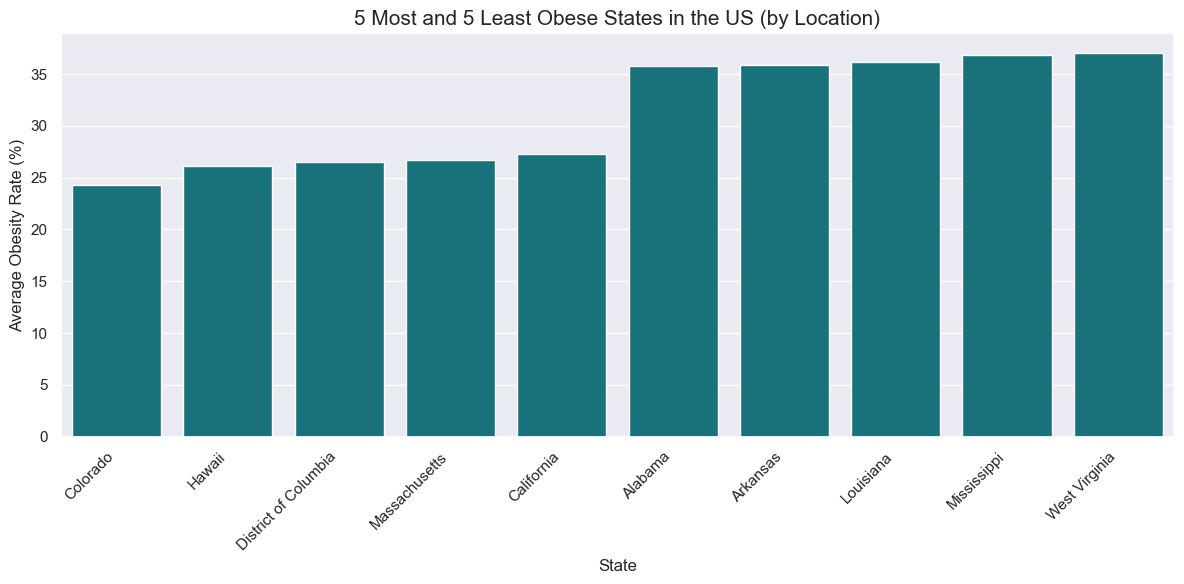

In [37]:
# 3.4 Bar Graph of 5 Most and 5 Least Obese States using LocationDesc

# Based on obesity question (Q036: Percent of adults aged 18 years and older who have obesity)

if "QuestionID" in df.columns and "LocationDesc" in df.columns:
    obesity_data = df[df["QuestionID"] == "Q036"]
    state_obesity = obesity_data.groupby("LocationDesc")["PrevalenceRate"].mean().sort_values()
    top_5_obese = state_obesity.tail(5)
    bottom_5_obese = state_obesity.head(5)
    combined_obese = pd.concat([bottom_5_obese, top_5_obese])
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x=combined_obese.index, y=combined_obese.values, color="#087E8B")
    plt.title("5 Most and 5 Least Obese States in the US (by Location)", size=15)
    plt.xlabel("State")
    plt.ylabel("Average Obesity Rate (%)")
    plt.xticks(rotation=45, ha="right")
    print("\nInsight: Bar graph shows states with highest and lowest obesity rates, highlighting regional health disparities\n")
    plt.tight_layout()
    plt.show()
    plt.close()
else:
      print("Required columns ('QuestionID', 'LocationDesc') for obesity states bar graph not found.")



Insight: Geographic plot reveals spatial patterns in PrevalenceRate, e.g., regional differences in obesity rates.


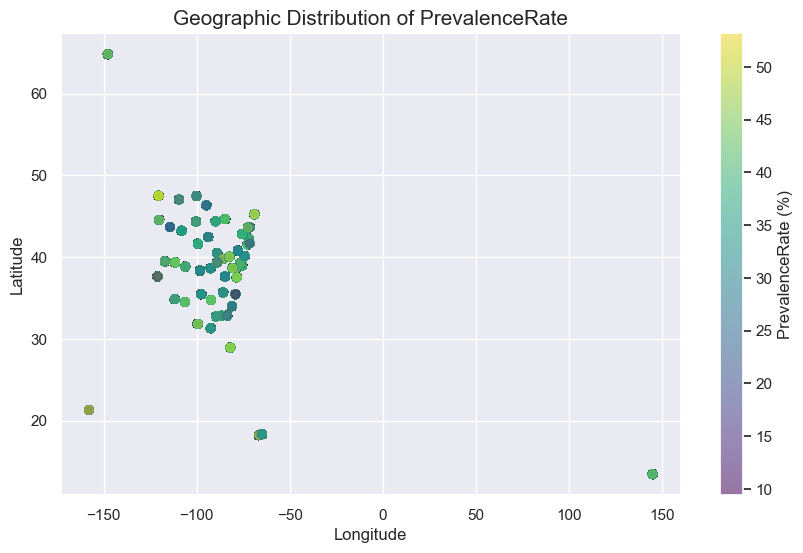

In [38]:
# 3.5 Latitude vs. Longitude colored by PrevalenceRate
if 'Latitude' in df.columns and 'Longitude' in df.columns:
    plt.figure(figsize=(10, 6))
    plt.scatter(df['Longitude'], df['Latitude'],c=df['PrevalenceRate'],cmap='viridis', alpha=0.5)
    plt.colorbar(label='PrevalenceRate (%)')
    plt.title('Geographic Distribution of PrevalenceRate', size=15)
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    print("\nInsight: Geographic plot reveals spatial patterns in PrevalenceRate, e.g., regional differences in obesity rates.")
    plt.show()
    plt.close()

## 4 Model Selection and Training

In [40]:
# 4.1 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTraining Set Shape:",X_train.shape)
print("Testing Set Shape:", X_test.shape)


Training Set Shape: (80184, 9)
Testing Set Shape: (20046, 9)


In [41]:
# Random Forest Regressor

rf = RandomForestRegressor(random_state=42)
rf_param_grid = {
    'n_estimators': [50,100],
    'max_depth': [10, 20],
    'min_samples_split': [2,5]
}
rf_grid = GridSearchCV(rf, rf_param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=2)
rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
print("\nBest Random Forest Parameters:", rf_grid.best_params_)
print("Cross Validation RMSE (Random Forest):", np.sqrt(-rf_grid.best_score_)) 
y_pred_rf = rf_best.predict(X_test)



Best Random Forest Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 100}
Cross Validation RMSE (Random Forest): 3.459611268216877


In [42]:
# Gradient Boosting Regressor (XGBoost)

xgb = XGBRegressor(random_state=42)
xgb_param_grid = {
    'n_estimators': [50, 100],  
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 6]
}
xgb_grid = GridSearchCV(xgb, xgb_param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=2)
xgb_grid.fit(X_train, y_train)
xgb_best = xgb_grid.best_estimator_
print("\nBest XGBoost Parameters:", xgb_grid.best_params_)
print("Cross-Validation RMSE (XGBoost):", np.sqrt(-xgb_grid.best_score_))
y_pred_xgb = xgb_best.predict(X_test)



Best XGBoost Parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 100}
Cross-Validation RMSE (XGBoost): 3.9097233355868672


## 5. Model Performance Evaluation

In [44]:
# 5.1 Evaluation Metrics
def evaluate_model(y_true, y_pred, model_name):
    rmse =np.sqrt(mean_squared_error(y_true, y_pred))
    mae =mean_absolute_error(y_true, y_pred)
    r2 =r2_score(y_true, y_pred)
    print(f"\n{model_name} Performance:")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R²: {r2:.2f}")
    return rmse, mae, r2

rf_metrics = evaluate_model(y_test, y_pred_rf, "Random Forest")
xgb_metrics = evaluate_model(y_test, y_pred_xgb, "XGBoost")


Random Forest Performance:
RMSE: 3.35
MAE: 2.22
R²: 0.84

XGBoost Performance:
RMSE: 3.88
MAE: 2.84
R²: 0.79


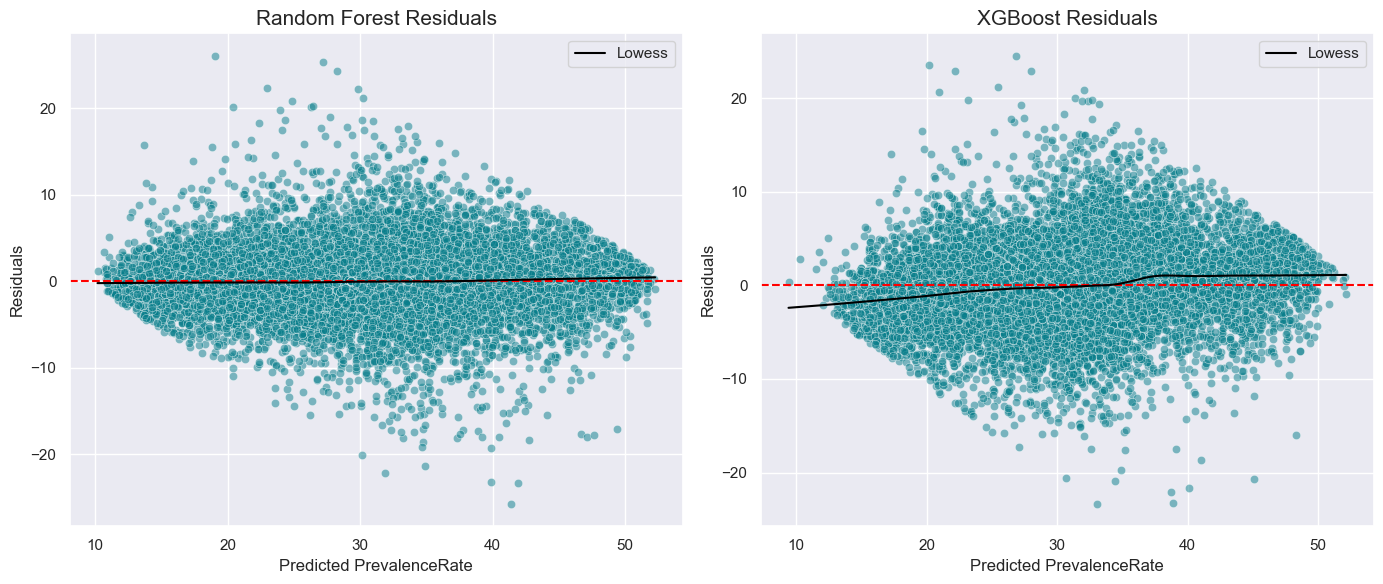

In [45]:
# 5.2 Residual Plots
plt.figure(figsize=(14, 6))

# Random Forest Residuals
plt.subplot(1, 2, 1)
rf_residuals = y_test - y_pred_rf
sns.scatterplot(x=y_pred_rf, y=rf_residuals, alpha=0.5, color='#087E8B')
plt.axhline(0, color='red', linestyle='--')
lowess_fit = lowess.lowess(rf_residuals, y_pred_rf, frac=0.3)
plt.plot(lowess_fit[:, 0], lowess_fit[:, 1], color='black', label='Lowess')
plt.title('Random Forest Residuals', size=15)
plt.xlabel('Predicted PrevalenceRate')
plt.ylabel('Residuals')
plt.legend()


# XGBoost Residuals
plt.subplot(1, 2, 2)
xgb_residuals = y_test - y_pred_xgb
sns.scatterplot(x=y_pred_xgb, y=xgb_residuals, alpha=0.5, color='#087E8B')
plt.axhline(0, color='red', linestyle='--')
lowess_fit = lowess.lowess(xgb_residuals, y_pred_xgb, frac=0.3)
plt.plot(lowess_fit[:, 0], lowess_fit[:, 1], color='black', label='Lowess')
plt.title('XGBoost Residuals', size=15)
plt.xlabel('Predicted PrevalenceRate')
plt.ylabel('Residuals')
plt.legend()

plt.tight_layout()
plt.show()
plt.close()



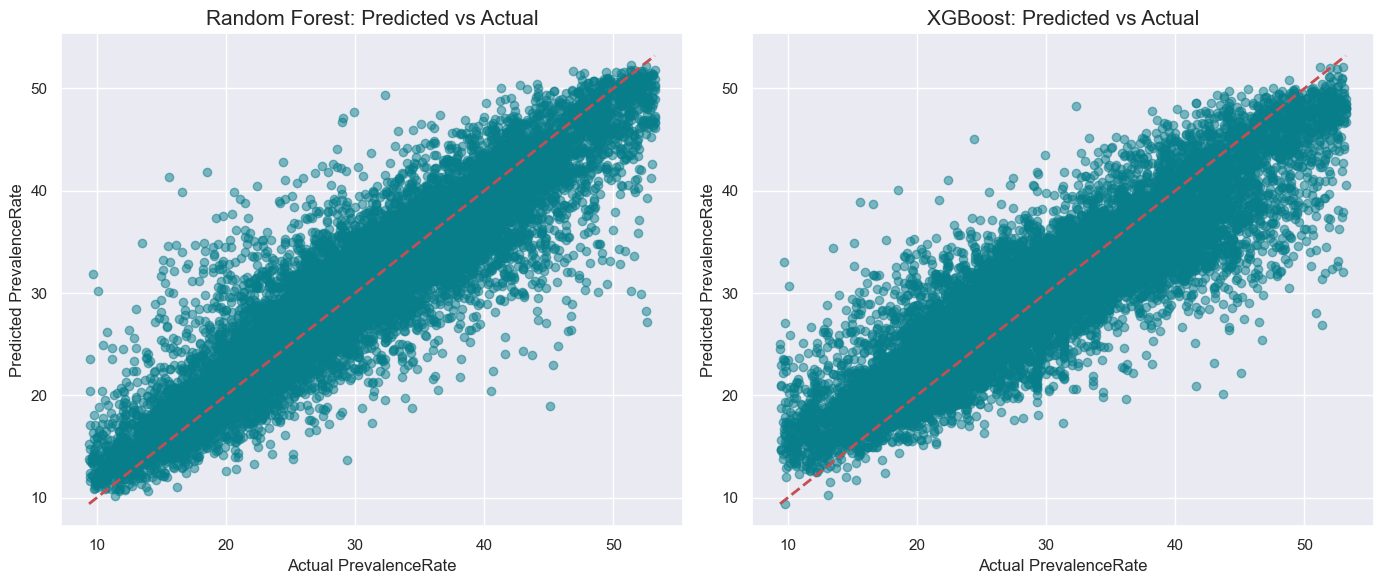

In [46]:
# 5.3 Predicted vs. Actual Plots
plt.figure(figsize=(14,6))

# Random Forest Predicted vs Actual
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='#087E8B')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Random Forest: Predicted vs Actual', size=15)
plt.xlabel('Actual PrevalenceRate')
plt.ylabel('Predicted PrevalenceRate')


# XGBoost Predicted vs Actual
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_xgb, alpha=0.5, color='#087E8B')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('XGBoost: Predicted vs Actual', size=15)
plt.xlabel('Actual PrevalenceRate')
plt.ylabel('Predicted PrevalenceRate')
plt.tight_layout()
plt.show()
plt.close()


 Feature Importance

 Insight: Top Random Forest features (e.g., QuestionID_encoded, Latitude) drive predictions.


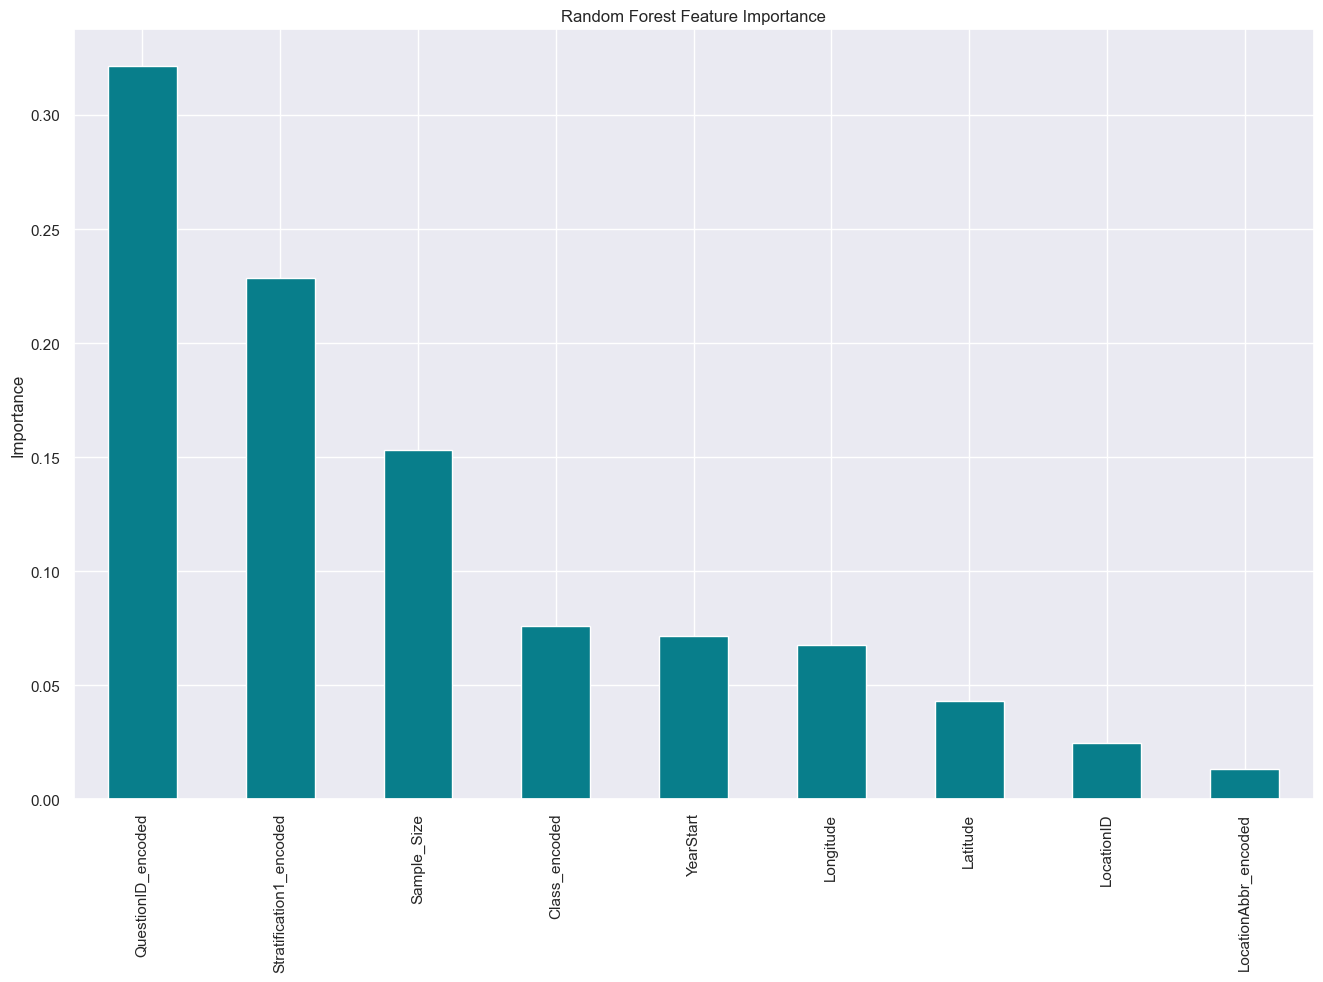


Insight: XGBoost highlights similar key features, confirming their predictive power.


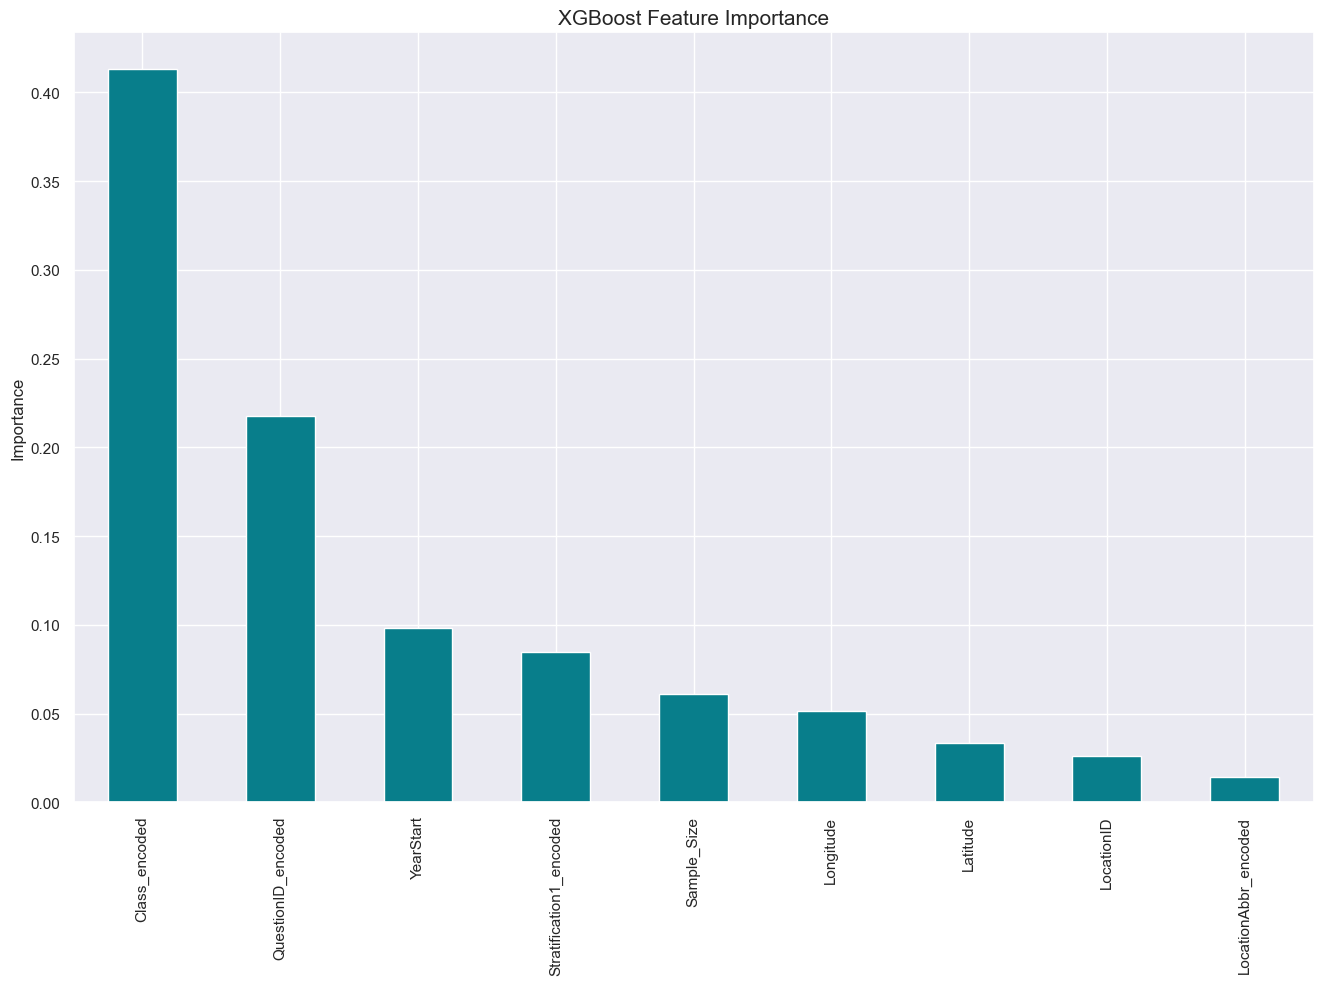

In [47]:
# 5.4 Feature Importance

#Plot feature importance for both models to identify key predictors.

print("\n Feature Importance")

# Random Forest Feature Importance
plt.figure(figsize=(16, 10))
rf_importance =pd.Series(rf_best.feature_importances_, index=features)
rf_importance.sort_values(ascending=False).plot(kind='bar',color='#087E8B')
plt.title('Random Forest Feature Importance',size=12)
plt.ylabel('Importance')
print("\n Insight: Top Random Forest features (e.g., QuestionID_encoded, Latitude) drive predictions.")
plt.show()
plt.close()

# XGBoost Feature Importance
plt.figure(figsize=(16, 10))
xgb_importance = pd.Series(xgb_best.feature_importances_, index=features)
xgb_importance.sort_values(ascending=False).plot(kind='bar', color='#087E8B')
plt.title('XGBoost Feature Importance', size=15)
plt.ylabel('Importance')
print("\nInsight: XGBoost highlights similar key features, confirming their predictive power.")
plt.show()
plt.close()
